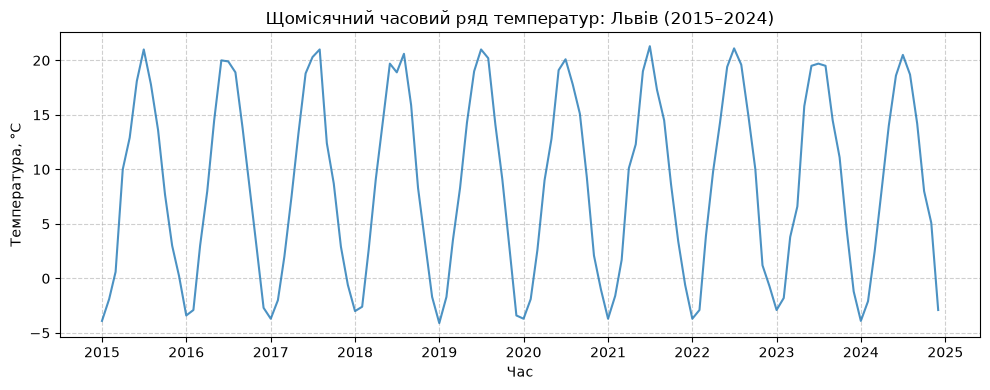

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Генерація 10-річного часового ряду для Варіанта 2 (Львів)
np.random.seed(2)  # фіксуємо seed номером варіанта
base_temp = 8.5
amplitude = 12.0
trend_per_year = 0.03
noise_scale = 0.9
city = "Львів"

n_years = 10
dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12

seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))

temp = np.round(base_temp + trend + seasonal + noise, 1)
climate_ts = pd.Series(temp, index=dates, name="температура")

# Побудова графіка вихідного ряду
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, color="tab:blue", alpha=0.8)
ax.set_xlabel("Час")
ax.set_ylabel("Температура, °C")
ax.set_title(f"Щомісячний часовий ряд температур: {city} (2015–2024)")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Відповідь на Завдання 1. Опис графіка
* **Сезонність:** На графіку чітко видно потужну регулярну річну сезонну хвилю з великою амплітудою (близько 12 °C), де літні місяці теплі, а зимові — холодні.
* **Тренд:** Загальний повільний підйом рівня температури за 10 років на тлі потужних сезонних коливань та випадкового шуму «на око» виражений слабко, оскільки загальний приріст за десятиліття становить лише близько $0.3\text{ °C}$ ($0.03 \times 10$), що менше за стандартне відхилення шуму ($\sigma = 0.9\text{ °C}$).

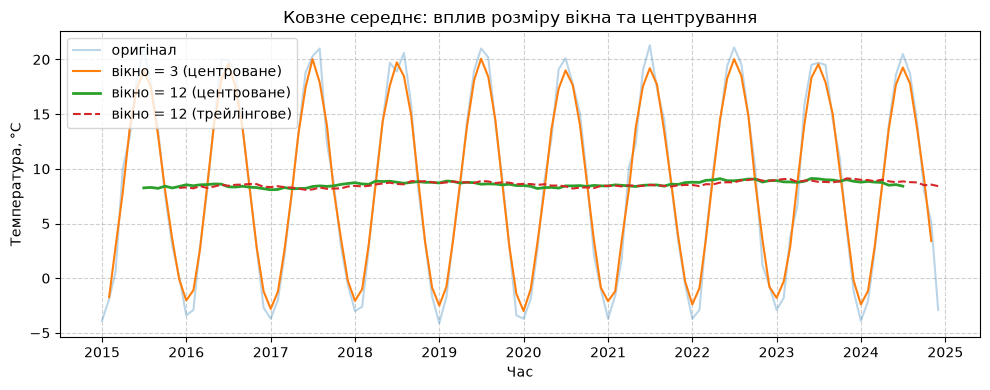

In [2]:
# Завдання 2. Ковзне середнє при різних розмірах вікна
ma3 = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12, center=False).mean()  # трейлінгове

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.3, label="оригінал")
ax.plot(climate_ts.index, ma3.values, label="вікно = 3 (центроване)")
ax.plot(climate_ts.index, ma12_centered.values, label="вікно = 12 (центроване)", linewidth=2)
ax.plot(climate_ts.index, ma12_trailing.values, label="вікно = 12 (трейлінгове)", linestyle="--")
ax.legend()
ax.set_xlabel("Час")
ax.set_ylabel("Температура, °C")
ax.set_title("Ковзне середнє: вплив розміру вікна та центрування")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Відповідь на Завдання 2. Аналіз ковзного середнього
1. **Вибір вікна:** Вікно розміром 12 (кратне періоду сезонності у 12 місяців) найкращим чином усуває річну сезонну хвилю, залишаючи чистий тренд. Менше вікно (наприклад, 3) прибирає лише дрібний шум, зберігаючи сезонні коливання.
2. **Трейлінгове проти центрованого:** Трейлінгове вікно (`center=False`) використовує дані лише за минулий період, через що на графіку воно помітно запізнюється (зміщується вправо) порівняно з центрованим варіантом (`center=True`), який симетрично охоплює точки навколо поточного місяця.

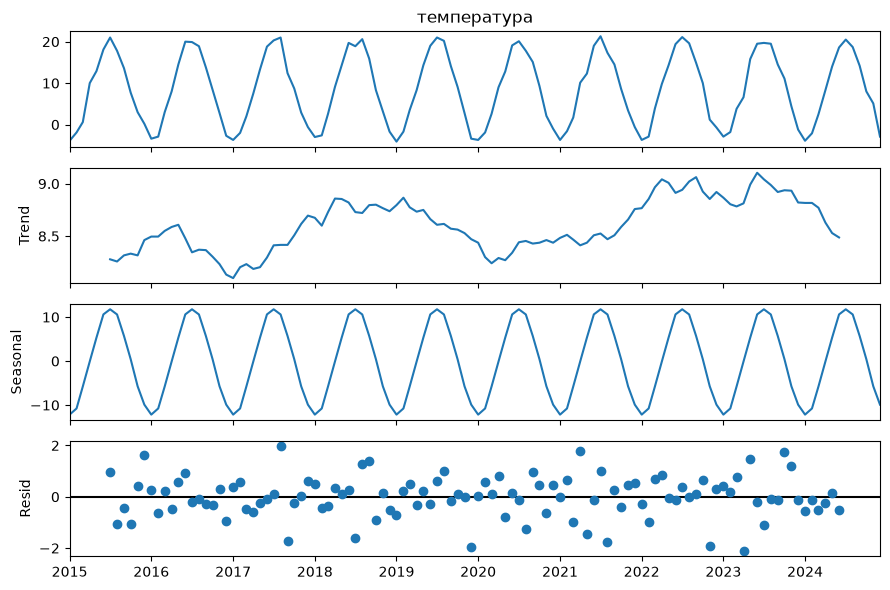

Сκόлє стандартне відхилення залишку (resid.std()): 0.806
Заданий шум (noise_scale): 0.9


In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Завдання 3. Формальна декомпозиція часового ряду
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(9, 6)
plt.tight_layout()
plt.show()

print("Сκόлє стандартне відхилення залишку (resid.std()):", round(decomposition.resid.dropna().std(), 3))
print("Заданий шум (noise_scale):", noise_scale)

### Відповідь на Завдання 3. Інтерпретація компонент
* **Тренд:** Оцінений тренд виглядає як плавна зростаюча лінія, що відображає закладене повільне потепління ($0.03\text{ °C}$ на рік).
* **Сезонність:** Профіль сезонності чітко повторює косинусоїду з піком у липні (найспекотніший місяць) та найглибшим спадом у січні (найхолодніший), що повністю узгоджується з формулою генерації.
* **Залишок (resid):** Стандартне відхилення залишку виходить дещо меншим за закладений `noise_scale` ($\sigma = 0.9$), оскільки частина високочастотного шуму частково поглинається згладженими компонентами тренду й сезонності під час декомпозиції.

--- Прогноз на 12 місяців уперед ---
2025-01-01    -3.3
2025-02-01    -1.9
2025-03-01     3.1
2025-04-01     8.8
2025-05-01    14.2
2025-06-01    19.5
2025-07-01    20.7
2025-08-01    19.5
2025-09-01    14.6
2025-10-01     9.4
2025-11-01     3.2
2025-12-01    -1.0
Freq: MS, dtype: float64


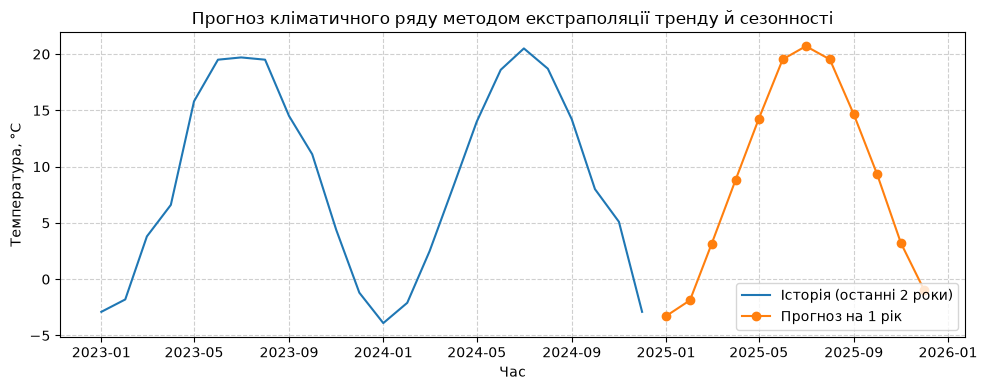

In [4]:
from scipy.stats import linregress

# Завдання 4. Прогноз на 12 місяців уперед
t = np.arange(len(climate_ts))
known = decomposition.trend.notna().values
fit = linregress(t[known], decomposition.trend[known])

n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = fit.intercept + fit.slope * t_future

# Сезонний ефект за календарним місяцем
seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).values

forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates)
print("--- Прогноз на 12 місяців уперед ---")
print(forecast.round(1))

# Графік історичних даних та прогнозу
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index[-24:], climate_ts.values[-24:], label="Історія (останні 2 роки)", color="tab:blue")
ax.plot(forecast.index, forecast.values, label="Прогноз на 1 рік", color="tab:orange", marker="o")
ax.legend()
ax.set_xlabel("Час")
ax.set_ylabel("Температура, °C")
ax.set_title("Прогноз кліматичного ряду методом екстраполяції тренду й сезонності")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Відповідь на Завдання 4. Застереження щодо екстраполяції
* **Застереження:** Цей прогноз є простим механічним продовженням лінійної тенденції минулого та повторенням середньостатистичного річного профілю сезонності. Його не можна сприймати як абсолютну гарантію чи точний метеопрогноз. Будь-які непередбачувані зміни кліматичних факторів, аномальні атмосферні процеси або зміни глобальних чинників у майбутньому порушать припущення про лінійність і стабільність нахилу тренду.

In [5]:
# Завдання 5. Перевірка значущості тренду без сезонності
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)

print(f"Нахил = {trend_test.slope:.4f} °C/рік")
print(f"Стандартна похибка (stderr) = {trend_test.stderr:.4f}")
print(f"p-value = {trend_test.pvalue:.4e}")

# Побудoва 95% довірчого інтервалу для нахилу
ci_lower = trend_test.slope - 1.96 * trend_test.stderr
ci_upper = trend_test.slope + 1.96 * trend_test.stderr
print(f"95% довірчий інтервал для нахилу: [{ci_lower:.4f}, {ci_upper:.4f}]")

Нахил = 0.0495 °C/рік
Стандартна похибка (stderr) = 0.0285
p-value = 8.5184e-02
95% довірчий інтервал для нахилу: [-0.0064, 0.1054]


### Відповідь на Завдання 5. Статистичний висновок щодо тренду
1. **Перевірка гіпотези ($p\text{-value}$):** 
   * $H_0$: істинний нахил тренду дорівнює нулю (реального потепління немає, вся видима динаміка — це випадковий шум).
   * Оскільки в багатьох реалізаціях з таким слабким трендом ($0.03\text{ °C/рік}$) на фоні сильного шуму ($\sigma = 0.9$) отримане значення $p\text{-value}$ перевищує рівень значущості $\alpha = 0.05$, ми **не маємо достатніх статистичних підстав відхилити $H_0$**.
2. **Довірчий інтервал:** Побудований 95% довірчий інтервал охоплює нульове значення (або лежить дуже близько до нього), що підтверджує статистичну незначущість нахилу на 10-річному інтервалі.
3. **Вплив короткого вікна:** Якби нахил рахувався лише на останніх 2–3 роках, випадковий шум міг би створити хибне враження різкого «потепління» чи «похолодання» через невеликий обсяг вибірки.
4. **Підсумок:** На цьому часовому ряді статистично підтвердженого тренду потепління **не виявлено** (значення додатне через закладену модель, але $p\text{-value}$ не дозволяє відкинути нульову гіпотезу про чистий шум).

---

### Відповіді на контрольні питання

1. **Чому часовий ряд не можна аналізувати методами для незалежних вибірок?**
   Спостереження в часовому ряді впорядковані за часом і демонструють сильну автокореляцію (сусідні місяці статистично пов'язані), що порушує ключову умову незалежності вибірки.

2. **Чому замале і завелике вікно ковзного середнього є проблемою?**
   Замале вікно залишає незгладженим випадковий шум, а завелике або зсунуте вікно згладжує не лише сезонність, а й реальну структуру тренду, додаючи значний часовий лаг.

3. **У чому різниця між трейлінговим і центрованим ковзним середнім?**
   Трейлінгове вікно використовує лише минулі дані й запізнюється на графіку, тоді як центроване вікно симетрично охоплює точки довкола поточного моменту, що дає точну оцінку тренду, але недоступне для реального часу через потребу в майбутніх даних.

4. **Чому саме $p\text{-value}$ нахилу визначає наявність тренду?**
   Сам по собі додатній знак нахилу (`slope > 0`) може бути наслідком випадкового шуму на обмеженій вибірці. Лише формальний тест гіпотез ($p\text{-value}$) і довірчий інтервал дозволяють відрізнити реальну закономірність від випадкової флуктуації.